# RQ1 — Route–airline clustering

In [1]:
# Imports and notebook setup 
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

# Limit the CPU-detection warning 
os.environ["LOKY_MAX_CPU_COUNT"] = "4"

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.config import FLIGHTS_PARQUET
from src.data_loading import load_flights


In [2]:
df = load_flights(FLIGHTS_PARQUET)

print("Number of flights:", len(df))
display(df.head())


Number of flights: 7079081


,fl_date,op_unique_carrier,origin,dest,origin_state_nm,dest_state_nm,cancellation_code,month,day_of_month,day_of_week,...,crs_arr_time,crs_elapsed_time,distance,dep_delay,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2024-01-01,9E,JFK,DTW,New York,Michigan,<NA>,1,1,1,...,1508,136.0,509.0,-5.0,-19.0,0.0,0.0,0.0,0.0,0.0
1,2024-01-01,9E,MSP,CLE,Minnesota,Ohio,<NA>,1,1,1,...,1325,130.0,622.0,-14.0,-30.0,0.0,0.0,0.0,0.0,0.0
2,2024-01-01,9E,JFK,RIC,New York,Virginia,<NA>,1,1,1,...,1601,106.0,288.0,-4.0,-20.0,0.0,0.0,0.0,0.0,0.0
3,2024-01-01,9E,RIC,JFK,Virginia,New York,<NA>,1,1,1,...,1841,111.0,288.0,-7.0,-42.0,0.0,0.0,0.0,0.0,0.0
4,2024-01-01,9E,DTW,MKE,Michigan,Wisconsin,<NA>,1,1,1,...,1034,79.0,237.0,-5.0,-14.0,0.0,0.0,0.0,0.0,0.0


## Aggregate flights into route–airline combinations
Instead of one row per flight, we want one row per combination of origin, destination and airline.
We will calculate distance, scheduled flight duration, flight frequency and scheduling patterns.

In [3]:
# removed cancelled and diverted flights from this initial 
# analysis because we want consistent observed-flight records
flights = df.loc[
    (df["cancelled"] == 0)
    & (df["diverted"] == 0)
    & (df["distance"] > 0)
    & (df["crs_elapsed_time"] > 0)
].copy()

# Convert scheduled departure time from HHMM to hour
flights["dep_hour"] = (
    flights["crs_dep_time"] // 100
)

# Keep only valid hours, allowing 2400 as midnight
flights = flights.loc[
    flights["dep_hour"].between(0, 24)
].copy()

flights["dep_hour"] = flights["dep_hour"] % 24

# Create scheduling indicators
flights["evening"] = (
    flights["dep_hour"] >= 18
).astype(int)

flights["weekend"] = (
    flights["day_of_week"].isin([6, 7])
).astype(int)

# Group by route and airline
route_data = (
    flights.groupby(
        ["origin", "dest", "op_unique_carrier"],
        observed=True
    )
    .agg(
        n_flights=("distance", "size"),
        mean_distance=("distance", "mean"),
        mean_duration=("crs_elapsed_time", "mean"),
        evening_share=("evening", "mean"),
        weekend_share=("weekend", "mean"),
    )
    .reset_index()
)

print("Number of route-airline combinations:", len(route_data))
display(route_data.head(10))


Number of route-airline combinations: 13239


,origin,dest,op_unique_carrier,n_flights,mean_distance,mean_duration,evening_share,weekend_share
0,ABE,ATL,9E,1001,692.0,136.536469,0.001998,0.257742
1,ABE,BNA,G4,103,685.0,133.990295,0.203883,0.485437
2,ABE,CLT,OH,1148,481.0,115.461670,0.145470,0.284843
3,ABE,DEN,G4,84,1539.0,242.761902,0.000000,0.500000
4,ABE,FLL,G4,81,1041.0,179.358032,0.049383,0.432099
5,ABE,MCO,G4,65,906.0,153.446152,0.000000,0.492308
6,ABE,MLB,G4,102,914.0,174.186279,0.000000,0.019608
7,ABE,MYR,G4,185,518.0,101.378380,0.070270,0.291892
8,ABE,ORD,OO,299,655.0,149.297653,0.000000,0.264214
9,ABE,PGD,G4,191,1018.0,173.670151,0.329843,0.246073


## Check the aggregated data
Before using K-means, we need to see how many flights each route–airline combination contains.

In [4]:
print(route_data["n_flights"].describe())

# How many combinations have very few flights?
print(
    "Combinations with fewer than 30 flights:",
    (route_data["n_flights"] < 30).sum()
)

# Check missing values
print(route_data.isna().sum())


count    13239.000000
mean       526.117305
std        678.582384
min          1.000000
25%         80.500000
50%        307.000000
75%        706.000000
max       7532.000000
Name: n_flights, dtype: float64
Combinations with fewer than 30 flights: 2032
origin               0
dest                 0
op_unique_carrier    0
n_flights            0
mean_distance        0
mean_duration        0
evening_share        0
weekend_share        0
dtype: int64


In [5]:
route_data = route_data.loc[
    route_data["n_flights"] >= 30
].copy()

print("Combinations retained:", len(route_data))


Combinations retained: 11207


In [6]:
features = [
    "mean_distance",
    "mean_duration",
    "n_flights",
    "evening_share",
    "weekend_share"
]

X = route_data[features].copy()

# Standardize the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Start with 4 clusters
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

route_data["cluster"] = kmeans.fit_predict(X_scaled)

# Number of route-airline combinations in each cluster
print(route_data["cluster"].value_counts().sort_index())

# Average characteristics of each cluster
display(
    route_data.groupby("cluster")[features].mean().round(2)
)


cluster
0    3843
1    5407
2     213
3    1744
Name: count, dtype: int64


,mean_distance,mean_duration,n_flights,evening_share,weekend_share
cluster,,,,,
0,612.109985,119.900002,1091.63,0.39,0.27
1,729.330017,134.270004,324.22,0.08,0.29
2,1101.449951,175.070007,61.25,0.09,0.87
3,2028.630005,288.600006,564.13,0.27,0.29


In [7]:
# Create delay indicator
flights["delayed_15"] = (
    flights["arr_delay"] >= 15
).astype(int)

# Calculate delay statistics for each route-airline combination
delay_stats = (
    flights.groupby(
        ["origin", "dest", "op_unique_carrier"],
        observed=True
    )
    .agg(
        delay_rate=("delayed_15", "mean"),
        mean_arr_delay=("arr_delay", "mean"),
        median_arr_delay=("arr_delay", "median"),
        std_arr_delay=("arr_delay", "std")
    )
    .reset_index()
)

# Combine delay statistics with clustering results
route_with_delays = route_data.merge(
    delay_stats,
    on=["origin", "dest", "op_unique_carrier"],
    how="left",
    validate="one_to_one"
)

# Compare delay patterns between clusters
cluster_delays = (
    route_with_delays.groupby("cluster")
    .agg(
        n_routes=("delay_rate", "size"),
        avg_delay_rate=("delay_rate", "mean"),
        avg_arr_delay=("mean_arr_delay", "mean"),
        median_arr_delay=("median_arr_delay", "median")
    )
    .round(3)
)

display(cluster_delays)


,n_routes,avg_delay_rate,avg_arr_delay,median_arr_delay
cluster,,,,
0,3843,0.225,9.414,-6.0
1,5407,0.198,6.698,-7.0
2,213,0.257,9.966,-3.0
3,1744,0.226,7.179,-6.0


In [8]:
results = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    db_score = davies_bouldin_score(X_scaled, labels)

    sil_score = silhouette_score(
        X_scaled,
        labels,
        sample_size=3000,
        random_state=42
    )

    results.append({
        "k": k,
        "davies_bouldin": db_score,
        "silhouette": sil_score,
        "inertia": model.inertia_
    })

evaluation = pd.DataFrame(results)

display(evaluation.round(3))


,k,davies_bouldin,silhouette,inertia
0,2,1.262,0.374,41609.722
1,3,1.413,0.247,34680.761
2,4,1.185,0.269,28883.724
3,5,1.035,0.305,23472.526
4,6,1.023,0.272,20280.865
5,7,0.990,0.287,18391.848
6,8,1.036,0.268,16617.572
7,9,1.006,0.279,15139.286
8,10,1.020,0.280,14002.133


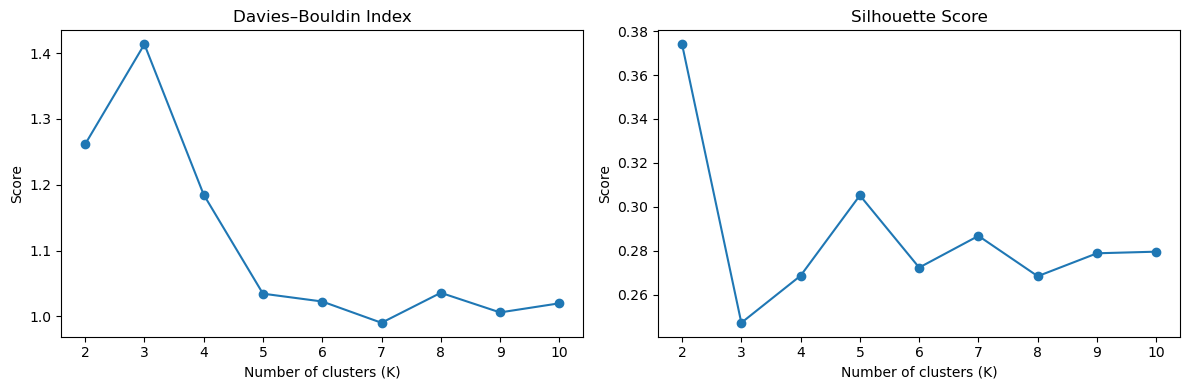

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(
    evaluation["k"],
    evaluation["davies_bouldin"],
    marker="o"
)
axes[0].set_title("Davies–Bouldin Index")
axes[0].set_xlabel("Number of clusters (K)")
axes[0].set_ylabel("Score")

axes[1].plot(
    evaluation["k"],
    evaluation["silhouette"],
    marker="o"
)
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (K)")
axes[1].set_ylabel("Score")

plt.tight_layout()
plt.show()


In [10]:
for k in [5, 7]:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    temp = route_data.copy()
    temp["cluster"] = labels

    print(f"\n========== K = {k} ==========")

    print("\nCluster sizes:")
    print(temp["cluster"].value_counts().sort_index())

    print("\nAverage operational characteristics:")
    display(
        temp.groupby("cluster")[features]
        .mean()
        .round(2)
    )



========== K = 5 ==========

Cluster sizes:
cluster
0    1520
1    1625
2    5346
3    2505
4     211
Name: count, dtype: int64

Average operational characteristics:


,mean_distance,mean_duration,n_flights,evening_share,weekend_share
cluster,,,,,
0,665.679993,126.160004,1990.67,0.23,0.27
1,2067.120117,292.890015,522.19,0.26,0.30
2,719.979980,133.300003,358.90,0.07,0.29
3,644.950012,123.800003,454.78,0.50,0.28
4,1103.380005,175.229996,60.65,0.09,0.88



========== K = 7 ==========

Cluster sizes:
cluster
0    1562
1     964
2    3897
3     725
4     158
5    2670
6    1231
Name: count, dtype: int64

Average operational characteristics:


,mean_distance,mean_duration,n_flights,evening_share,weekend_share
cluster,,,,,
0,712.179993,132.220001,371.85,0.61,0.27
1,2374.550049,328.980011,582.79,0.32,0.29
2,464.959991,102.559998,491.75,0.13,0.27
3,966.950012,159.139999,118.36,0.13,0.48
4,1117.750000,176.919998,57.44,0.08,0.95
5,1177.219971,188.550003,422.14,0.10,0.27
6,677.590027,127.800003,2164.19,0.23,0.27


,mean_distance,mean_duration,n_flights,evening_share,weekend_share
mean_distance,1.000,0.986,-0.093,0.040,0.093
mean_duration,0.986,1.000,-0.090,0.035,0.084
n_flights,-0.093,-0.090,1.000,0.040,-0.163
evening_share,0.040,0.035,0.040,1.000,-0.078
weekend_share,0.093,0.084,-0.163,-0.078,1.000


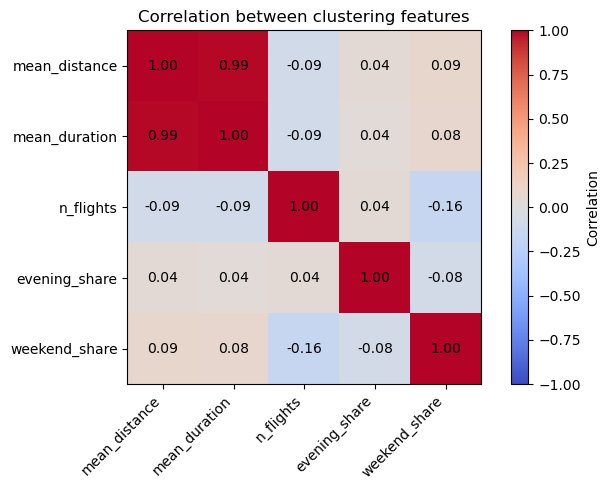

In [11]:
corr = route_data[features].corr()

display(corr.round(3))

plt.figure(figsize=(7, 5))
plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
plt.colorbar(label="Correlation")
plt.xticks(range(len(features)), features, rotation=45, ha="right")
plt.yticks(range(len(features)), features)

for i in range(len(features)):
    for j in range(len(features)):
        plt.text(j, i, f"{corr.iloc[i, j]:.2f}",
                 ha="center", va="center")

plt.title("Correlation between clustering features")
plt.tight_layout()
plt.show()


In [12]:
# Remove mean_duration because it is highly correlated with distance
features_4 = [
    "mean_distance",
    "n_flights",
    "evening_share",
    "weekend_share"
]

X_4 = route_data[features_4]

scaler_4 = StandardScaler()
X_scaled_4 = scaler_4.fit_transform(X_4)

results_4 = []

for k in range(2, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled_4)

    results_4.append({
        "k": k,
        "davies_bouldin": davies_bouldin_score(X_scaled_4, labels),
        "silhouette": silhouette_score(
            X_scaled_4,
            labels,
            sample_size=3000,
            random_state=42
        )
    })

evaluation_4 = pd.DataFrame(results_4)

display(evaluation_4.round(3))


,k,davies_bouldin,silhouette
0,2,1.692,0.241
1,3,1.293,0.283
2,4,1.072,0.314
3,5,0.945,0.329
4,6,1.041,0.291
5,7,0.969,0.311
6,8,0.959,0.317
7,9,1.013,0.283
8,10,0.949,0.293


In [13]:
# Fit K-means with 5 clusters and 4 features
final_kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

route_data["cluster"] = final_kmeans.fit_predict(X_scaled_4)

# Number of combinations per cluster
print("Cluster sizes:")
display(
    route_data["cluster"].value_counts().sort_index()
)

# Average characteristics
print("Cluster characteristics:")
display(
    route_data.groupby("cluster")[features_4]
    .mean()
    .round(2)
)


Cluster sizes:


cluster
0    5798
1    1426
2    1674
3    2099
4     210
Name: count, dtype: int64

Cluster characteristics:


,mean_distance,n_flights,evening_share,weekend_share
cluster,,,,
0,683.530029,380.43,0.09,0.29
1,2035.290039,486.01,0.15,0.30
2,705.619995,1943.91,0.23,0.27
3,853.619995,371.38,0.59,0.28
4,1095.140015,60.27,0.09,0.88


In [14]:
# Merge the updated clusters with delay statistics
route_with_delays = route_data[
    ["origin", "dest", "op_unique_carrier", "cluster", "n_flights"]
].merge(
    delay_stats,
    on=["origin", "dest", "op_unique_carrier"],
    how="left",
    validate="one_to_one"
)

# Compare delay patterns across clusters
cluster_delays = (
    route_with_delays.groupby("cluster")
    .agg(
        n_routes=("delay_rate", "size"),
        avg_delay_rate=("delay_rate", "mean"),
        avg_arr_delay=("mean_arr_delay", "mean"),
        median_arr_delay=("median_arr_delay", "median")
    )
    .round(3)
)

display(cluster_delays)


,n_routes,avg_delay_rate,avg_arr_delay,median_arr_delay
cluster,,,,
0,5798,0.197,6.580,-7.0
1,1426,0.216,6.049,-6.0
2,1674,0.209,6.914,-6.0
3,2099,0.253,12.669,-5.0
4,210,0.257,9.985,-3.0


In [15]:
# Flight-weighted delay rate
weighted_delay = (
    route_with_delays.groupby("cluster")
    .apply(
        lambda g: np.average(
            g["delay_rate"],
            weights=g["n_flights"]
        ),
        include_groups=False
    )
    .rename("weighted_delay_rate")
)

display(
    pd.concat([cluster_delays, weighted_delay], axis=1).round(3)
)


,n_routes,avg_delay_rate,avg_arr_delay,median_arr_delay,weighted_delay_rate
cluster,,,,,
0,5798,0.197,6.580,-7.0,0.195
1,1426,0.216,6.049,-6.0,0.208
2,1674,0.209,6.914,-6.0,0.209
3,2099,0.253,12.669,-5.0,0.242
4,210,0.257,9.985,-3.0,0.254


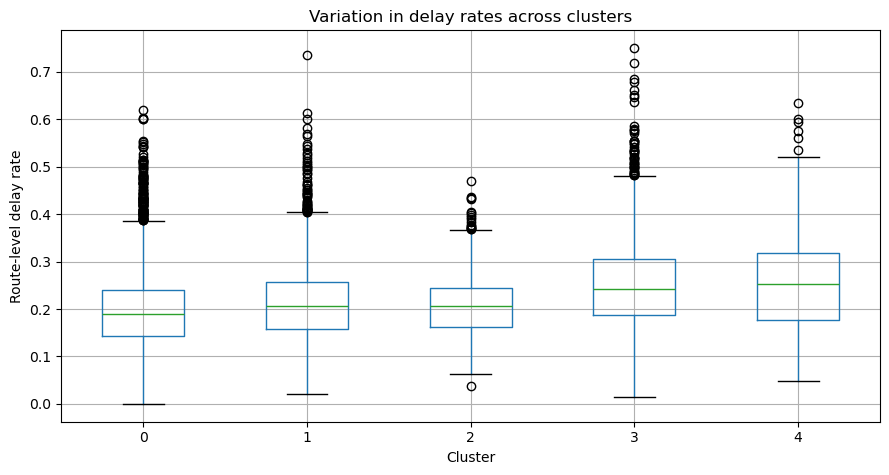

In [16]:
ax = route_with_delays.boxplot(
    column="delay_rate",
    by="cluster",
    figsize=(9, 5)
)

ax.set_title("Variation in delay rates across clusters")
ax.set_xlabel("Cluster")
ax.set_ylabel("Route-level delay rate")

plt.suptitle("")
plt.tight_layout()
plt.show()


In [17]:
# How much variation in delay rates is explained by cluster membership?
overall_mean = route_with_delays["delay_rate"].mean()

cluster_means = route_with_delays.groupby("cluster")["delay_rate"].mean()
cluster_sizes = route_with_delays.groupby("cluster")["delay_rate"].size()

ss_between = (
    cluster_sizes * (cluster_means - overall_mean)**2
).sum()

ss_total = (
    (route_with_delays["delay_rate"] - overall_mean)**2
).sum()

eta_squared = ss_between / ss_total

print(f"Eta-squared: {eta_squared:.4f}")
print(f"Variation explained by clusters: {eta_squared*100:.2f}%")


Eta-squared: 0.0666
Variation explained by clusters: 6.66%


In [18]:
# Reuse the four features defined in the comparison section.
# Use the standardized data from the final model
reference_labels = route_data["cluster"].to_numpy()

seeds = [0, 1, 2, 3, 4, 42, 100, 123, 2024, 2026]

stability_results = []

for seed in seeds:
    model = KMeans(
        n_clusters=5,
        random_state=seed,
        n_init=10
    )

    new_labels = model.fit_predict(X_scaled_4)

    ari = adjusted_rand_score(
        reference_labels,
        new_labels
    )

    stability_results.append({
        "seed": seed,
        "ARI": ari
    })

stability_df = pd.DataFrame(stability_results)

display(stability_df.round(4))

print(
    "Mean ARI:",
    round(stability_df["ARI"].mean(), 4)
)


,seed,ARI
0,0,0.9944
1,1,0.9977
2,2,0.9888
3,3,0.9996
4,4,0.9661
5,42,1.0000
6,100,0.9946
7,123,0.9786
8,2024,0.9614
9,2026,0.9996


Mean ARI: 0.9881


In [19]:
# Rebuild the original route-airline aggregation
route_data_all = (
    flights.groupby(
        ["origin", "dest", "op_unique_carrier"],
        observed=True
    )
    .agg(
        n_flights=("distance", "size"),
        mean_distance=("distance", "mean"),
        mean_duration=("crs_elapsed_time", "mean"),
        evening_share=("evening", "mean"),
        weekend_share=("weekend", "mean")
    )
    .reset_index()
)

threshold_results = []

for threshold in [30, 50, 100]:

    temp = route_data_all[
        route_data_all["n_flights"] >= threshold
    ].copy()

    X_temp = StandardScaler().fit_transform(
        temp[features_4]
    )

    model = KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    )

    temp["cluster"] = model.fit_predict(X_temp)

    threshold_results.append({
        "threshold": threshold,
        "n_combinations": len(temp),
        "davies_bouldin": davies_bouldin_score(
            X_temp, temp["cluster"]
        ),
        "silhouette": silhouette_score(
            X_temp,
            temp["cluster"],
            sample_size=min(3000, len(temp)),
            random_state=42
        )
    })

threshold_df = pd.DataFrame(threshold_results)

display(threshold_df.round(3))


,threshold,n_combinations,davies_bouldin,silhouette
0,30,11207,0.945,0.329
1,50,10651,0.990,0.329
2,100,9436,1.008,0.317


In [20]:
keys = ["origin", "dest", "op_unique_carrier"]

reference = route_data[keys + ["cluster"]].rename(
    columns={"cluster": "reference_cluster"}
)

for threshold in [50, 100]:
    temp = route_data_all.loc[
        route_data_all["n_flights"] >= threshold
    ].copy()

    scaled = StandardScaler().fit_transform(
        temp[features_4]
    )

    temp["new_cluster"] = KMeans(
        n_clusters=5,
        random_state=42,
        n_init=10
    ).fit_predict(scaled)

    comparison = reference.merge(
        temp[keys + ["new_cluster"]],
        on=keys,
        how="inner",
        validate="one_to_one"
    )

    ari = adjusted_rand_score(
        comparison["reference_cluster"],
        comparison["new_cluster"]
    )

    print(
        f"Threshold {threshold}: "
        f"{len(comparison)} shared combinations, "
        f"ARI = {ari:.4f}"
    )


Threshold 50: 10651 shared combinations, ARI = 0.8388
Threshold 100: 9436 shared combinations, ARI = 0.8098


In [21]:
output_dir = project_root / "results" / "tables"
output_dir.mkdir(parents=True, exist_ok=True)

# Route-airline cluster assignments
route_data.to_csv(
    output_dir / "02_route_clusters.csv",
    index=False
)

# Cluster delay statistics
cluster_delays.to_csv(
    output_dir / "02_cluster_delay_summary.csv"
)

# K-means stability results
stability_df.to_csv(
    output_dir / "02_clustering_stability.csv",
    index=False
)

# Threshold sensitivity results
threshold_df.to_csv(
    output_dir / "02_threshold_sensitivity.csv",
    index=False
)

print("RQ1 results saved to:", output_dir)


RQ1 results saved to: c:\Users\harja\OneDrive - Danmarks Tekniske Universitet\DTU\Masters\Computational tools for data science\Project ideas\ComputationalToolsForDS\results\tables
